In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"

issuedupes = pd.read_csv(
    processed_dir / "issuedupes_clean.csv",
    low_memory=False
)

eclipse_issues = pd.read_csv(
    processed_dir / "eclipse_issues_clean.csv",
    low_memory=False
)

eclipse_pairs = pd.read_csv(
    processed_dir / "eclipse_duplicate_pairs.csv",
    low_memory=False
)

print("IssueDupesLite pairs:", issuedupes.shape)
print("Eclipse issues:", eclipse_issues.shape)
print("Eclipse direct duplicate pairs:", eclipse_pairs.shape)

IssueDupesLite pairs: (9957, 17)
Eclipse issues: (85156, 12)
Eclipse direct duplicate pairs: (13231, 17)


In [2]:
comparison = pd.DataFrame({
    "Metric": [
        "Dataset format",
        "Total records",
        "Known duplicate pairs",
        "Unique issues",
        "Empty text records"
    ],
    "IssueDupesLite": [
        "Issue pairs",
        len(issuedupes),
        len(issuedupes),
        pd.concat([
            issuedupes["primary_id"],
            issuedupes["duplicate_id"]
        ]).nunique(),
        (
            issuedupes["primary_text"].fillna("").eq("")
            | issuedupes["duplicate_text"].fillna("").eq("")
        ).sum()
    ],
    "Eclipse Platform": [
        "Individual issues",
        len(eclipse_issues),
        len(eclipse_pairs),
        eclipse_issues["Issue_id"].nunique(),
        eclipse_issues["issue_text"].fillna("").eq("").sum()
    ]
})

display(comparison)

,Metric,IssueDupesLite,Eclipse Platform
0,Dataset format,Issue pairs,Individual issues
1,Total records,9957,85156
2,Known duplicate pairs,9957,13231
3,Unique issues,19094,85156
4,Empty text records,0,1


In [3]:

issuedupes["primary_word_count"] = (
    issuedupes["primary_text"]
    .fillna("")
    .str.split()
    .str.len()
)

issuedupes["duplicate_word_count"] = (
    issuedupes["duplicate_text"]
    .fillna("")
    .str.split()
    .str.len()
)

eclipse_issues["word_count"] = (
    eclipse_issues["issue_text"]
    .fillna("")
    .str.split()
    .str.len()
)

issuedupes_lengths = pd.concat([
    issuedupes["primary_word_count"],
    issuedupes["duplicate_word_count"]
], ignore_index=True)

length_summary = pd.DataFrame({
    "IssueDupesLite": issuedupes_lengths.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ),
    "Eclipse Platform": eclipse_issues["word_count"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
})

display(length_summary)

,IssueDupesLite,Eclipse Platform
count,19914.000000,85156.000000
mean,149.784674,117.036451
std,347.584808,166.186453
min,1.000000,0.000000
50%,86.000000,78.000000
90%,282.000000,216.000000
95%,419.350000,303.000000
99%,1122.740000,813.000000
max,17688.000000,3820.000000


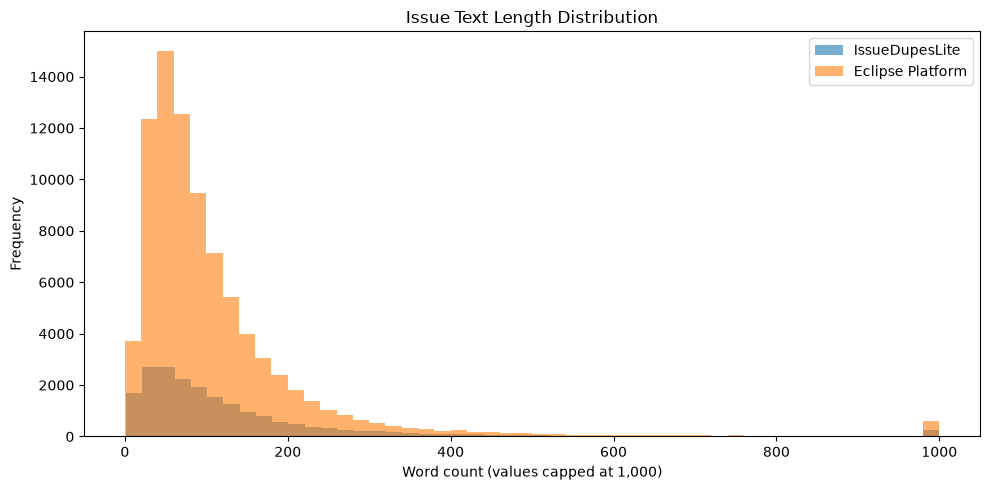

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    issuedupes_lengths.clip(upper=1000),
    bins=50,
    alpha=0.6,
    label="IssueDupesLite"
)

ax.hist(
    eclipse_issues["word_count"].clip(upper=1000),
    bins=50,
    alpha=0.6,
    label="Eclipse Platform"
)

ax.set_title("Issue Text Length Distribution")
ax.set_xlabel("Word count (values capped at 1,000)")
ax.set_ylabel("Frequency")
ax.legend()

plt.tight_layout()
plt.show()